# Phase 4 - Exploratory Data Analysis (Real Execution)

Source: `data/processed/cleaned_customer_churn.csv` (read-only).

All statistics are computed by the shared module `src/eda.py`; this notebook and
`outputs/reports/eda_report.txt` therefore use **identical calculations**. No hard-coded numbers.

Language convention: differences are reported as **observed** - no causal claims.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.eda as eda

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
print("Cleaned file:", eda.CLEAN_PATH)
print("Report target:", eda.REPORT_PATH)
print("Figures dir  :", eda.FIGURES_DIR)

Cleaned file: data\processed\cleaned_customer_churn.csv
Report target: outputs\reports\eda_report.txt
Figures dir  : outputs\figures


## 1. Load cleaned data

In [2]:
clean_hash_before = eda.sha256_of(eda.CLEAN_PATH)
print("Cleaned SHA-256 (before):", clean_hash_before)

df = eda.load_cleaned()
print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns (read-only)")
df.head()

Cleaned SHA-256 (before): 38e6f2dd278033a4617f880e8f11304c5fc6dce2c05ecef3f2a8bf48eeaa8996
Loaded 7043 rows x 21 columns (read-only)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 2. Dataset overview

In [3]:
print(f"Rows                 : {df.shape[0]}")
print(f"Columns              : {df.shape[1]}")
print("Dtypes:")
print(df.dtypes.to_string())
print(f"Missing values       : {int(df.isna().sum().sum())}")
print(f"Duplicate rows       : {int(df.duplicated().sum())}")
print(f"Duplicate customerIDs: {int(df['customerID'].duplicated().sum())}")

Rows                 : 7043
Columns              : 21
Dtypes:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
Missing values       : 0
Duplicate rows       : 0
Duplicate customerIDs: 0


## 3. Target / churn distribution

Total customers : 7043
Churned (1)     : 1869
Retained (0)    : 5174
Churn rate      : 26.5370%


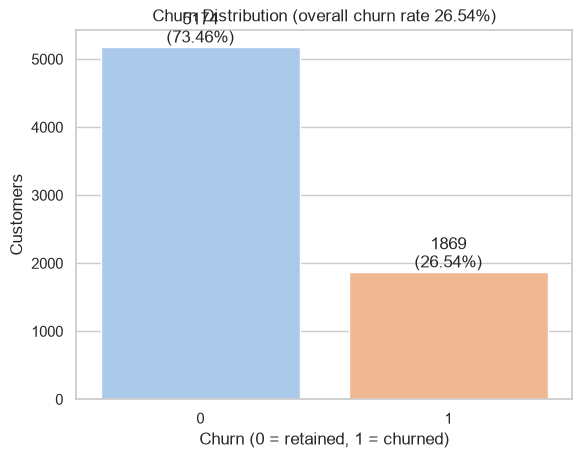

In [4]:
oc = eda.overall_churn(df)
print(f"Total customers : {oc['total']}")
print(f"Churned (1)     : {oc['churned']}")
print(f"Retained (0)    : {oc['retained']}")
print(f"Churn rate      : {oc['churn_rate_pct']:.4f}%")

eda.plot_churn_distribution(df)
plt.show()

## 4. Numerical feature analysis

Statistics for `tenure`, `MonthlyCharges`, `TotalCharges` split by churn class.

,churn,feature,count,mean,median,std,min,max
0,0,tenure,5174,37.5700,38.000,24.1138,0.00,72.00
1,1,tenure,1869,17.9791,10.000,19.5311,1.00,72.00
2,0,MonthlyCharges,5174,61.2651,64.425,31.0926,18.25,118.75
3,1,MonthlyCharges,1869,74.4413,79.650,24.6661,18.85,118.35
4,0,TotalCharges,5174,2549.9114,1679.525,2329.9542,0.00,8672.45
5,1,TotalCharges,1869,1531.7961,703.550,1890.8230,18.85,8684.80


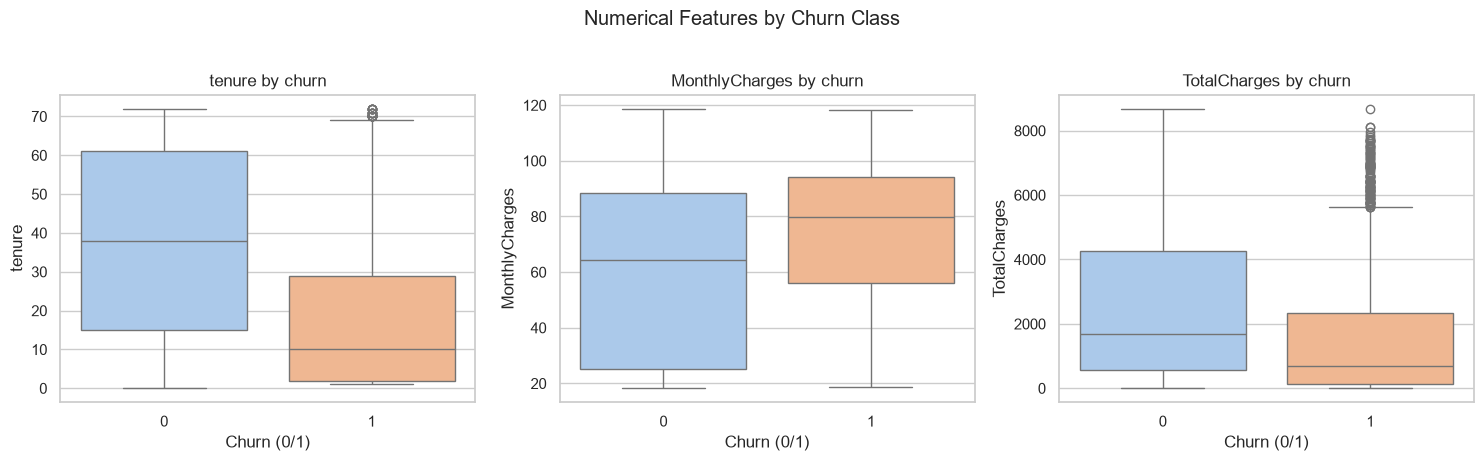

In [5]:
num_stats = eda.numeric_stats_by_churn(df)
display(num_stats)

eda.plot_numeric_by_churn(df)
plt.show()

## 5. Categorical feature analysis

For every categorical feature: customer count, churned count, retained count, churn rate.

Overall churn rate reference: 26.5370%

=== gender ===


,gender,customers,churned,retained,churn_rate_pct
0,Female,3488,939,2549,26.9209
1,Male,3555,930,2625,26.1603


=== SeniorCitizen ===


,SeniorCitizen,customers,churned,retained,churn_rate_pct
0,1,1142,476,666,41.6813
1,0,5901,1393,4508,23.6062


=== Partner ===


,Partner,customers,churned,retained,churn_rate_pct
0,No,3641,1200,2441,32.9580
1,Yes,3402,669,2733,19.6649


... (22 outputs left out)

=== PaperlessBilling ===


,PaperlessBilling,customers,churned,retained,churn_rate_pct
0,Yes,4171,1400,2771,33.5651
1,No,2872,469,2403,16.3301


=== PaymentMethod ===


,PaymentMethod,customers,churned,retained,churn_rate_pct
0,Electronic check,2365,1071,1294,45.2854
1,Mailed check,1612,308,1304,19.1067
2,Bank transfer (automatic),1544,258,1286,16.7098
3,Credit card (automatic),1522,232,1290,15.2431


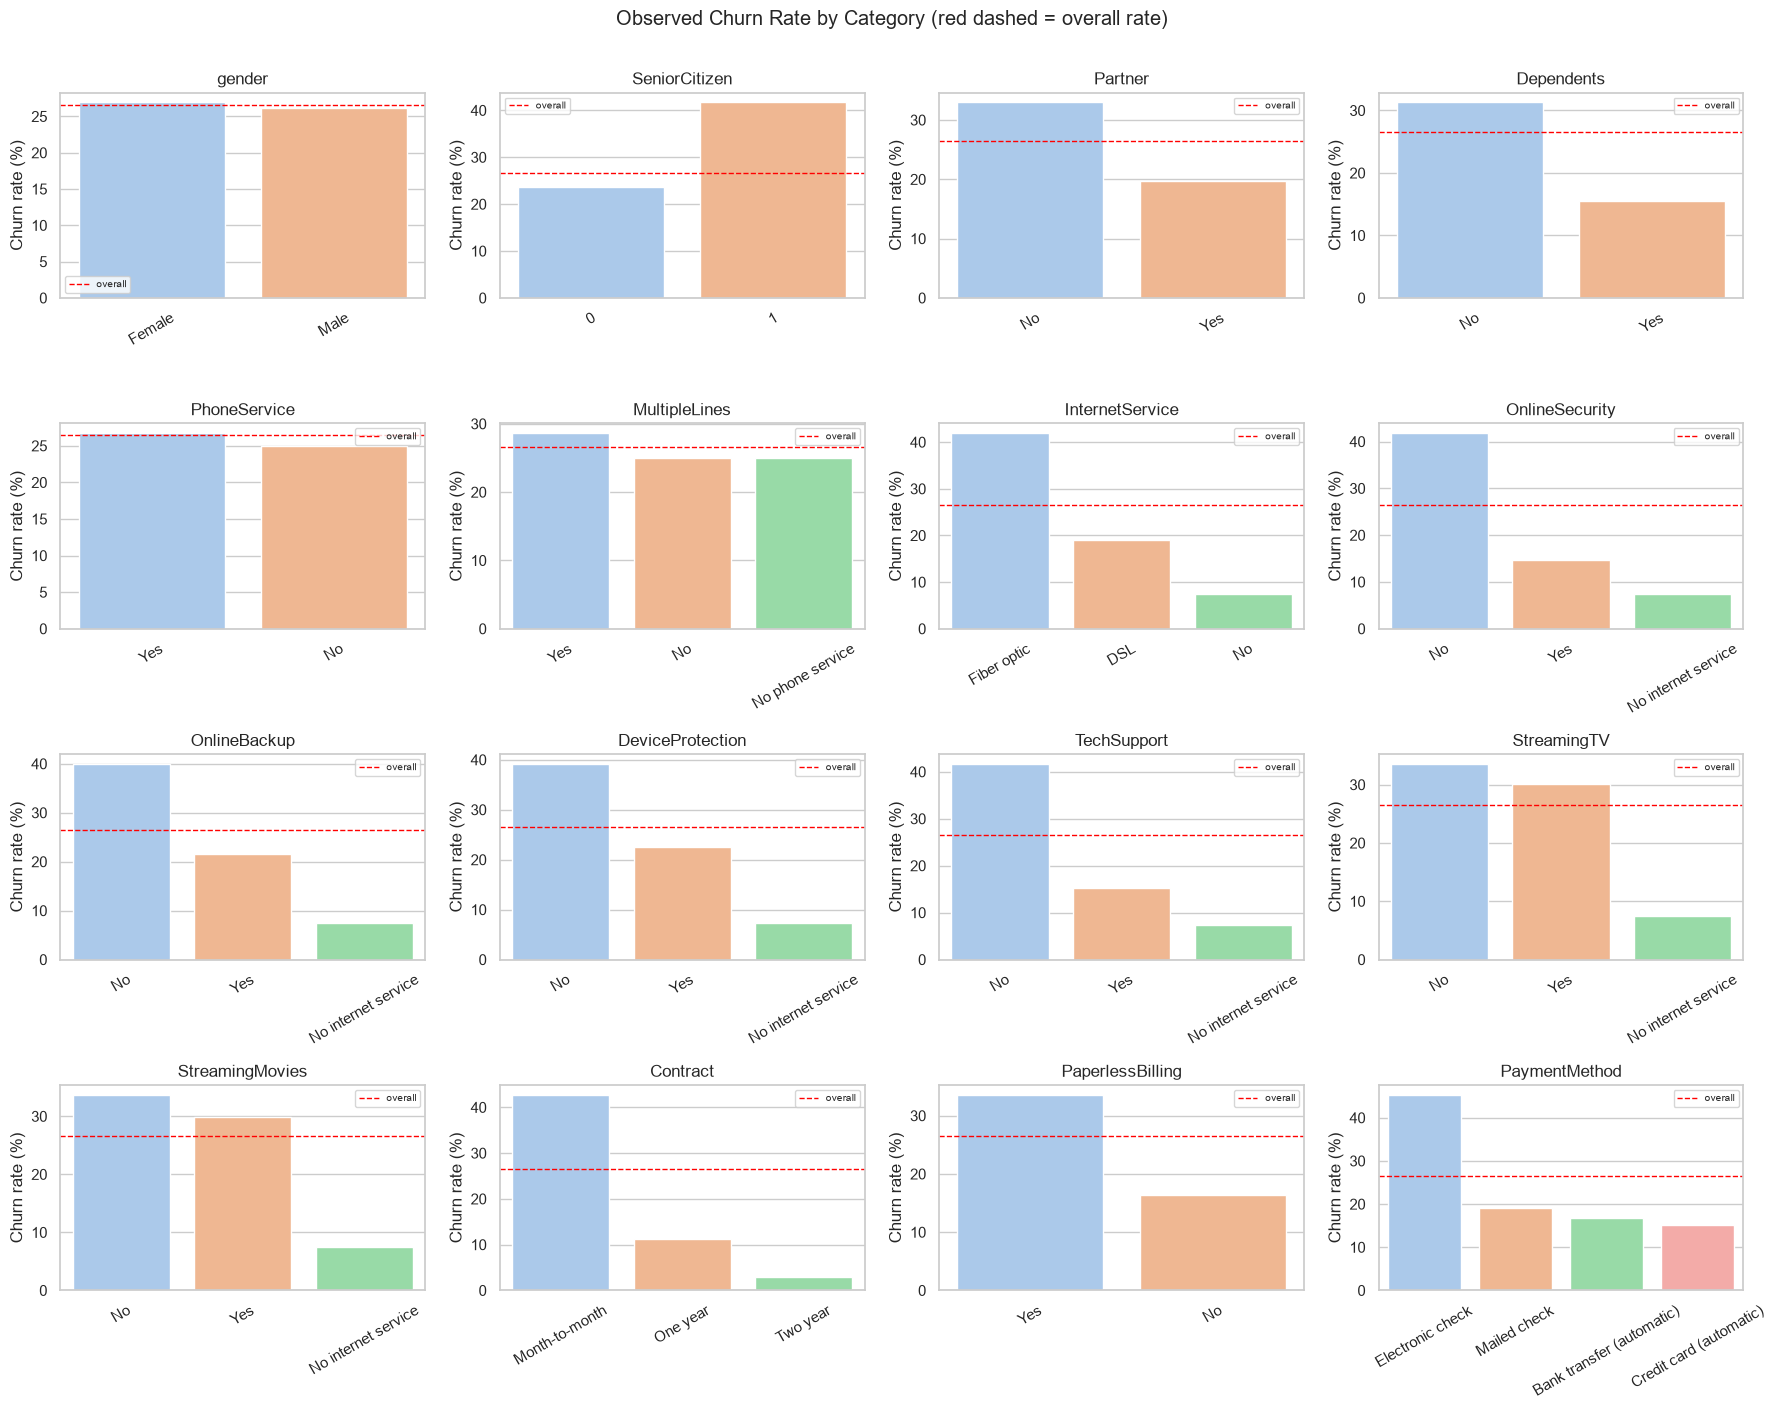

In [6]:
cat_tables = eda.categorical_summary(df)
print(f"Overall churn rate reference: {oc['churn_rate_pct']:.4f}%\n")
for col, t in cat_tables.items():
    print(f"=== {col} ===")
    display(t)

eda.plot_categorical_churn_rates(df)
plt.show()

## 6. Tenure analysis

Groups: 0-6 months (includes tenure = 0), 7-12, 13-24, 25+.

,TenureGroup,customers,churned,retained,churn_rate_pct
0,0-6 months,1481,784,697,52.9372
1,7-12 months,705,253,452,35.8865
2,13-24 months,1024,294,730,28.7109
3,25+ months,3833,538,3295,14.0360


tenure=0 customers included in '0-6 months': 11 customers


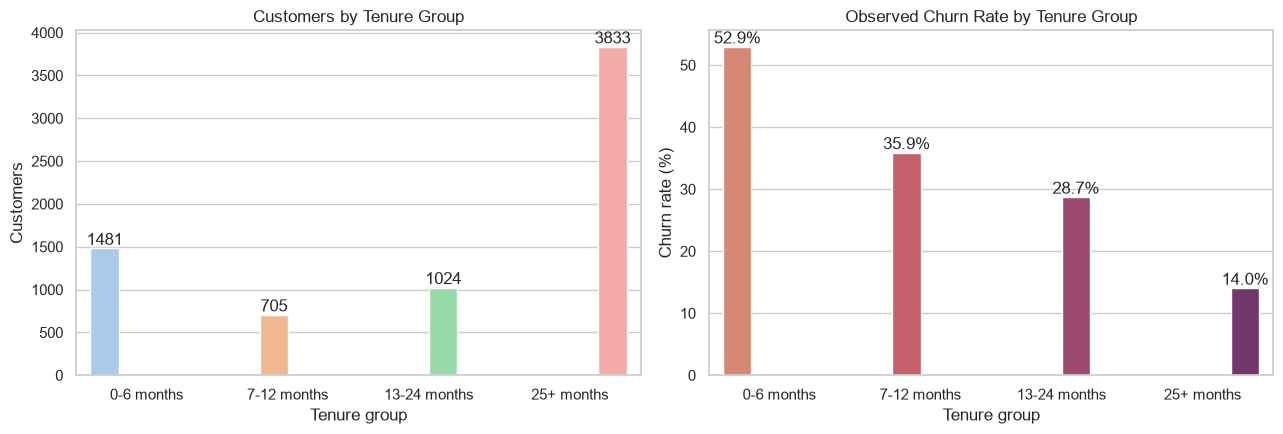

In [7]:
tenure_t = eda.tenure_group_analysis(df)
display(tenure_t)
print("tenure=0 customers included in '0-6 months':",
      int((df['tenure'] == 0).sum()), "customers")

eda.plot_tenure_groups(df)
plt.show()

## 7. Contract analysis

,Contract,customers,churned,retained,churn_rate_pct
0,Month-to-month,3875,1655,2220,42.7097
1,One year,1473,166,1307,11.2695
2,Two year,1695,48,1647,2.8319


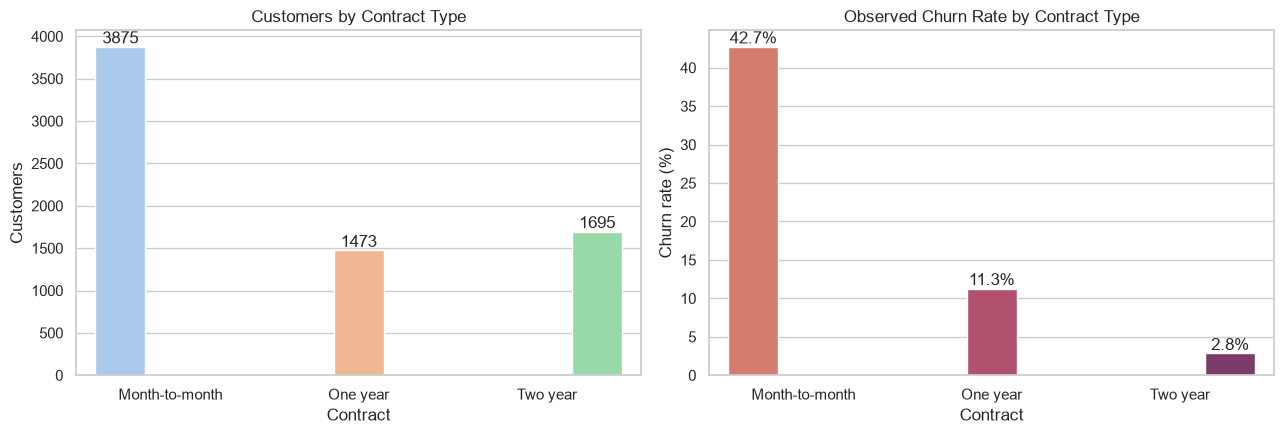

In [8]:
contract_t = eda.churn_table(df, "Contract")
contract_t["Contract"] = pd.Categorical(contract_t["Contract"], categories=eda.CONTRACT_ORDER, ordered=True)
contract_t = contract_t.sort_values("Contract").reset_index(drop=True)
display(contract_t)

eda.plot_contract(df)
plt.show()

## 8. Service analysis

Observed churn rates by service category - descriptive only, no causal claims.

In [9]:
for col in eda.SERVICE_COLUMNS:
    t = cat_tables[col]
    top = t.iloc[0]
    low = t.iloc[-1]
    print(f"{col:<18} highest observed churn: {str(top[col]):<18} {top['churn_rate_pct']:6.2f}% (n={int(top['customers']):4d}) | "
          f"lowest: {str(low[col]):<18} {low['churn_rate_pct']:6.2f}% (n={int(low['customers']):4d})")
print("\nNote: 'No internet service' rows overlap across add-on columns; comparisons are descriptive.")

PhoneService       highest observed churn: Yes                 26.71% (n=6361) | lowest: No                  24.93% (n= 682)
MultipleLines      highest observed churn: Yes                 28.61% (n=2971) | lowest: No phone service    24.93% (n= 682)
InternetService    highest observed churn: Fiber optic         41.89% (n=3096) | lowest: No                   7.41% (n=1526)
OnlineSecurity     highest observed churn: No                  41.77% (n=3498) | lowest: No internet service   7.41% (n=1526)
OnlineBackup       highest observed churn: No                  39.93% (n=3088) | lowest: No internet service   7.41% (n=1526)
DeviceProtection   highest observed churn: No                  39.13% (n=3095) | lowest: No internet service   7.41% (n=1526)
TechSupport        highest observed churn: No                  41.64% (n=3473) | lowest: No internet service   7.41% (n=1526)
StreamingTV        highest observed churn: No                  33.52% (n=2810) | lowest: No internet service   7.41% (n=1

## 9. Charge analysis

Churned vs retained on MonthlyCharges and TotalCharges, plus MonthlyCharges bands.
TotalCharges accumulates with tenure, so differences partly reflect tenure.

,churn,feature,count,mean,median,std,min,max
2,0,MonthlyCharges,5174,61.2651,64.425,31.0926,18.25,118.75
3,1,MonthlyCharges,1869,74.4413,79.650,24.6661,18.85,118.35
4,0,TotalCharges,5174,2549.9114,1679.525,2329.9542,0.00,8672.45
5,1,TotalCharges,1869,1531.7961,703.550,1890.8230,18.85,8684.80


,MonthlyChargesBand,customers,churned,retained,churn_rate_pct
0,<=35,1735,189,1546,10.8934
1,35.01-55,897,251,646,27.9822
2,55.01-75,1291,348,943,26.9558
3,75.01-95,1825,663,1162,36.3288
4,95.01+,1295,418,877,32.2780


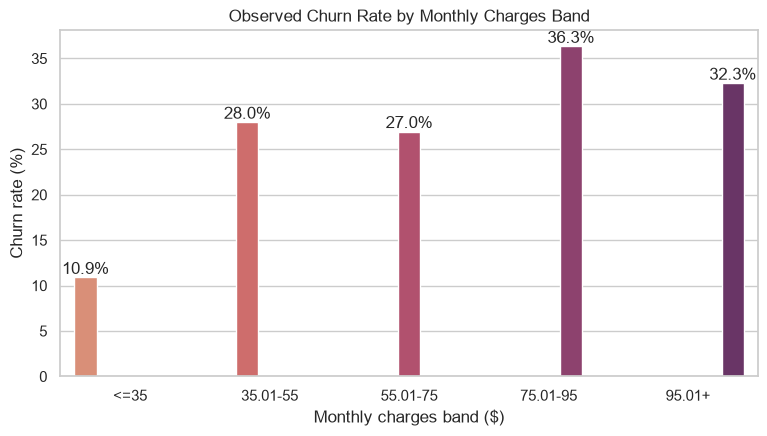

In [10]:
display(num_stats[num_stats["feature"].isin(["MonthlyCharges", "TotalCharges"])])

mc_t = eda.monthly_charges_band_analysis(df)
display(mc_t)

eda.plot_monthly_charges_bands(df)
plt.show()

## 10. Segment analysis

Contract x TenureGroup, Contract x InternetService, TenureGroup x InternetService.

=== Contract x TenureGroup ===


,Contract,TenureGroup,customers,churned,retained,churn_rate_pct
0,Month-to-month,0-6 months,1413,780,633,55.2017
1,Month-to-month,7-12 months,581,244,337,41.9966
2,Month-to-month,13-24 months,737,278,459,37.7205
3,Month-to-month,25+ months,1144,353,791,30.8566
4,One year,25+ months,1152,137,1015,11.8924
5,One year,7-12 months,85,9,76,10.5882
6,One year,0-6 months,39,4,35,10.2564
7,One year,13-24 months,197,16,181,8.1218
8,Two year,25+ months,1537,48,1489,3.1230
9,Two year,0-6 months,29,0,29,0.0000


=== Contract x InternetService ===


,Contract,InternetService,customers,churned,retained,churn_rate_pct
0,Month-to-month,Fiber optic,2128,1162,966,54.6053
1,Month-to-month,DSL,1223,394,829,32.2159
2,One year,Fiber optic,539,104,435,19.2950
3,Month-to-month,No,524,99,425,18.8931
4,One year,DSL,570,53,517,9.2982
5,Two year,Fiber optic,429,31,398,7.2261
6,One year,No,364,9,355,2.4725
7,Two year,DSL,628,12,616,1.9108
8,Two year,No,638,5,633,0.7837


=== TenureGroup x InternetService ===


,TenureGroup,InternetService,customers,churned,retained,churn_rate_pct
0,0-6 months,Fiber optic,620,460,160,74.1935
1,7-12 months,Fiber optic,303,185,118,61.0561
2,13-24 months,Fiber optic,449,219,230,48.7751
3,0-6 months,DSL,510,246,264,48.2353
4,25+ months,Fiber optic,1724,433,1291,25.1160
5,7-12 months,DSL,240,54,186,22.5000
6,0-6 months,No,351,78,273,22.2222
7,13-24 months,DSL,336,66,270,19.6429
8,7-12 months,No,162,14,148,8.6420
9,25+ months,DSL,1335,93,1242,6.9663


Highest observed churn segments (n >= 30):


,combination,segment,customers,churned,retained,churn_rate_pct
0,TenureGroup x InternetService,0-6 months | Fiber optic,620,460,160,74.1935
1,TenureGroup x InternetService,7-12 months | Fiber optic,303,185,118,61.0561
2,Contract x TenureGroup,Month-to-month | 0-6 months,1413,780,633,55.2017
3,Contract x InternetService,Month-to-month | Fiber optic,2128,1162,966,54.6053
4,TenureGroup x InternetService,13-24 months | Fiber optic,449,219,230,48.7751
5,TenureGroup x InternetService,0-6 months | DSL,510,246,264,48.2353
6,Contract x TenureGroup,Month-to-month | 7-12 months,581,244,337,41.9966
7,Contract x TenureGroup,Month-to-month | 13-24 months,737,278,459,37.7205
8,Contract x InternetService,Month-to-month | DSL,1223,394,829,32.2159
9,Contract x TenureGroup,Month-to-month | 25+ months,1144,353,791,30.8566


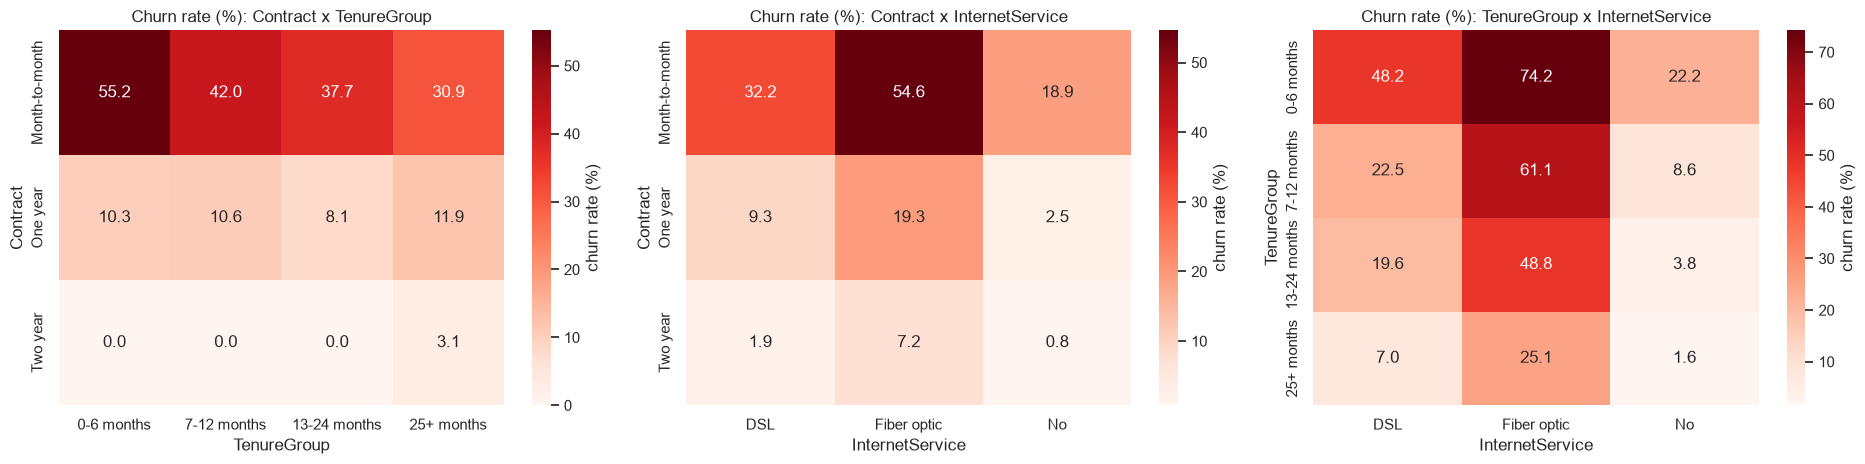

In [11]:
seg_ct = eda.segment_table(df, "Contract", "TenureGroup")
seg_ci = eda.segment_table(df, "Contract", "InternetService")
seg_ti = eda.segment_table(df, "TenureGroup", "InternetService")
print("=== Contract x TenureGroup ===")
display(seg_ct)
print("=== Contract x InternetService ===")
display(seg_ci)
print("=== TenureGroup x InternetService ===")
display(seg_ti)

top_seg = eda.top_segments(df)
print(f"Highest observed churn segments (n >= {eda.MIN_SEGMENT_N}):")
display(top_seg.head(10))

eda.plot_segment_heatmaps(df)
plt.show()

## 11. Correlation analysis

Numeric variables only: tenure, MonthlyCharges, TotalCharges (+ churn).

Pearson:


,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.0000,0.2479,0.8262,-0.3522
MonthlyCharges,0.2479,1.0000,0.6512,0.1934
TotalCharges,0.8262,0.6512,1.0000,-0.1983
Churn,-0.3522,0.1934,-0.1983,1.0000


Spearman:


,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.0000,0.2764,0.8897,-0.3671
MonthlyCharges,0.2764,1.0000,0.6380,0.1847
TotalCharges,0.8897,0.6380,1.0000,-0.2300
Churn,-0.3671,0.1847,-0.2300,1.0000


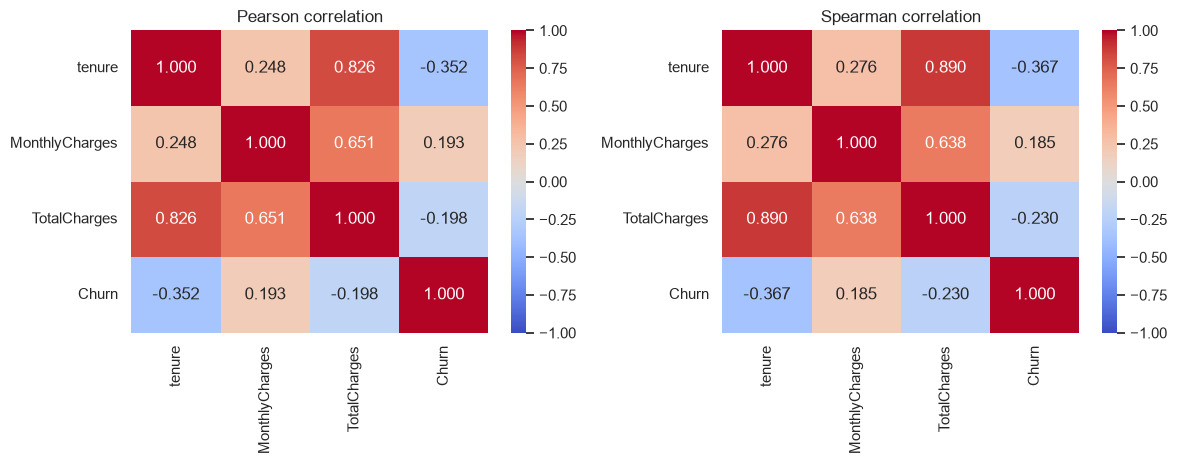

tenure-TotalCharges Pearson r = 0.8262: TotalCharges accumulates with tenure (expected, not causal).
tenure-Churn Pearson r = -0.3522: longer-tenured customers churned less in this dataset (observed association).


In [12]:
pearson, spearman = eda.correlation_analysis(df)
print("Pearson:")
display(pearson)
print("Spearman:")
display(spearman)

eda.plot_correlation_heatmap(df)
plt.show()

print(f"tenure-TotalCharges Pearson r = {pearson.loc['tenure', 'TotalCharges']:.4f}: "
      "TotalCharges accumulates with tenure (expected, not causal).")
print(f"tenure-Churn Pearson r = {pearson.loc['tenure', 'Churn']:.4f}: longer-tenured customers "
      "churned less in this dataset (observed association).")

## 12. Key findings

Observation -> Evidence -> Business implication (all values computed from the data).

In [13]:
findings = eda.key_findings(df)
for i, f in enumerate(findings, 1):
    print(f"{i}. {f}\n")

1. Overall churn: 1869/7043 customers churned (26.54%); 5174 retained. The target is moderately imbalanced.

2. Contract: month-to-month customers had an observed churn rate of 42.71% (n=3875), versus 11.27% for one-year and 2.83% for two-year contracts.

3. Tenure: customers with 0-6 months tenure had an observed churn rate of 52.94% (n=1481), versus 14.04% for 25+ months customers.

4. Internet service: Fiber optic users had an observed churn rate of 41.89% (n=3096), versus 18.96% for DSL and 7.41% for customers without internet service.

5. Payment method: electronic check users had an observed churn rate of 45.29%, the highest among payment methods; automatic-payment methods were below 16.71%.

6. Add-on services: customers WITHOUT OnlineSecurity had an observed churn rate of 41.77% vs 14.61% for those with it; without TechSupport 41.64% vs 15.17% with it.

7. Paperless billing: customers with paperless billing had an observed churn rate of 33.57% vs 16.33% without.

8. Senior citi

## 13. Business implications

In [14]:
for i, f in enumerate(eda.business_implications(df), 1):
    print(f"{i}. {f}\n")

1. Early-tenure focus: with 52.94% observed churn in the first 6 months versus 14.04% after 25 months, onboarding and early-life engagement are potentially high-leverage retention windows.

2. Contract strategy: month-to-month contracts show 42.71% observed churn versus 2.83% for two-year contracts; contract type is a potentially useful segmentation variable for retention campaigns.

3. Price positioning: churned customers had a higher mean monthly charge (74.44) than retained customers (61.27); price-sensitive segments may respond to targeted offers, though this is not evidence of causation.

4. Service bundling: lower observed churn among customers with security/backup/support add-ons suggests bundled value may associate with retention; test before treating as a driver.

5. Base to protect: 5174 retained customers generate the billing base; the 1869 churned customers represent the addressable retrospective pool for win-back analysis.

6. All implications are hypotheses for further an

## 14. Limitations

In [15]:
for i, f in enumerate(eda.limitations(), 1):
    print(f"{i}. {f}\n")

1. Observational, cross-sectional snapshot: observed differences do not establish causation.

2. Class imbalance: only about one in four customers churned (26.54%); this matters for later modeling (stratification, resampling, metrics).

3. 11 customers have tenure = 0 with TotalCharges set to 0 (verified during Phase 3 cleaning); their TotalCharges is a convention, not an observed billing amount.

4. TotalCharges accumulates with tenure (strong positive correlation with tenure), so comparing TotalCharges between churned and retained customers is confounded by tenure.

5. Segments with few customers have unstable churn rates; segment findings focus on groups with at least 30 customers.

6. Single-provider sample: results describe this dataset and may not generalize to other markets.

7. No temporal, pricing, or campaign data: churn dynamics and drivers over time cannot be studied here.

8. Categorical features with dependent category values (e.g., 'No internet service' rows in add-on co

## Report generation + data integrity check

Regenerates `outputs/reports/eda_report.txt` from the same functions used above,
then verifies the cleaned dataset is byte-for-byte unchanged.

In [16]:
eda.write_report(df, verbose=False)
print("Report written:", eda.REPORT_PATH, "exists =", eda.REPORT_PATH.exists())

clean_hash_after = eda.sha256_of(eda.CLEAN_PATH)
print("Cleaned SHA-256 (before):", clean_hash_before)
print("Cleaned SHA-256 (after) :", clean_hash_after)
assert clean_hash_before == clean_hash_after, "Cleaned dataset was modified!"
print("PASS: data/processed/cleaned_customer_churn.csv is byte-for-byte unchanged.")

figs = eda.FIGURE_FILES
missing = [f for f in figs if not (eda.FIGURES_DIR / f).exists()]
print(f"Figures on disk: {len(figs) - len(missing)}/{len(figs)}", "- ALL PRESENT" if not missing else f"- MISSING: {missing}")

Report written: outputs\reports\eda_report.txt exists = True
Cleaned SHA-256 (before): 38e6f2dd278033a4617f880e8f11304c5fc6dce2c05ecef3f2a8bf48eeaa8996
Cleaned SHA-256 (after) : 38e6f2dd278033a4617f880e8f11304c5fc6dce2c05ecef3f2a8bf48eeaa8996
PASS: data/processed/cleaned_customer_churn.csv is byte-for-byte unchanged.
Figures on disk: 8/8 - ALL PRESENT
